In [2]:
import numpy as np
import pandas as pd

df = pd.read_csv("/Users/rayyan/Desktop/honors_indep_study/Results/Clustering_Results_week3_contacts.csv")

print(df.shape)
print(df.columns.tolist())
print(df["particle_type"].value_counts())

(295616, 23)
['particle_id', 'x', 'y', 'Area', 'frame', 'cluster', 'cluster_size', 'particle_type', 'N_active', 'N_passive', 'active_fraction', 'cluster_num_AA_contacts', 'cluster_num_AP_contacts', 'cluster_num_PP_contacts', 'cm_x', 'cm_y', 'x_rel_CM', 'y_rel_CM', 'Rg_px', 'cluster_num_AA_contacts_all', 'cluster_num_AP_contacts_all', 'cluster_num_PP_contacts_all', 'cluster_total_contacts_pair_specific']
particle_type
active     148667
passive    146949
Name: count, dtype: int64


In [4]:
AA_CUT = 48  # px

frame_num = 51
f = df[(df["frame"] == frame_num) & (df["particle_type"] == "active")]
xy = f[["x", "y"]].to_numpy()

print(len(f), "active particles in frame", frame_num)
print(xy[:3])   # x, y of the first 3

374 active particles in frame 51
[[1101.947  956.135]
 [1660.672  998.453]
 [1584.314  888.093]]


In [5]:
dx = xy[:, 0][:, None] - xy[:, 0][None, :]   # x gap for every pair
dy = xy[:, 1][:, None] - xy[:, 1][None, :]   # y gap for every pair
d = np.sqrt(dx**2 + dy**2)

print(d.shape)
print(d[:3, :3].round(1))

(374, 374)
[[  0.  560.3 487.1]
 [560.3   0.  134.2]
 [487.1 134.2   0. ]]


In [6]:
np.fill_diagonal(d, np.inf)   # distance to itself = infinity, so it never counts

counts = (d <= AA_CUT).sum(axis=1)

print(counts[:10])
print(pd.Series(counts).value_counts().sort_index())

[2 1 1 1 1 1 1 1 3 1]
0     19
1    209
2    104
3     35
4      5
5      2
Name: count, dtype: int64


In [7]:
df["num_AA_neighbors_48px"] = np.nan   # passive particles stay blank

actives = df[df["particle_type"] == "active"]

for frame_num, f in actives.groupby("frame"):
    xy = f[["x", "y"]].to_numpy()

    dx = xy[:, 0][:, None] - xy[:, 0][None, :]
    dy = xy[:, 1][:, None] - xy[:, 1][None, :]
    d = np.sqrt(dx**2 + dy**2)
    np.fill_diagonal(d, np.inf)

    df.loc[f.index, "num_AA_neighbors_48px"] = (d <= AA_CUT).sum(axis=1)

print(df.loc[df["particle_type"] == "active", "num_AA_neighbors_48px"].value_counts().sort_index())
print("passive blanks:", df.loc[df["particle_type"] == "passive", "num_AA_neighbors_48px"].isna().all())

num_AA_neighbors_48px
0.0     7791
1.0    73875
2.0    49285
3.0    14887
4.0     2596
5.0      222
6.0       11
Name: count, dtype: int64
passive blanks: True


In [10]:
df["num_AA_neighbors_48px"] = np.nan
df["local_min_AA_distance_px"] = np.nan
df["local_mean_AA_distance_px"] = np.nan

actives = df[df["particle_type"] == "active"]

for frame_num, f in actives.groupby("frame"):
    xy = f[["x", "y"]].to_numpy()

    dx = xy[:, 0][:, None] - xy[:, 0][None, :]
    dy = xy[:, 1][:, None] - xy[:, 1][None, :]
    d = np.sqrt(dx**2 + dy**2)
    np.fill_diagonal(d, np.inf)

    counts = (d <= AA_CUT).sum(axis=1)

    # keep only distances within 48 px; everything else becomes NaN
    near = np.where(d <= AA_CUT, d, np.nan)

    has = counts > 0                          # particles with at least one neighbour
    mins = np.full(len(f), np.nan)
    means = np.full(len(f), np.nan)
    mins[has] = np.nanmin(near[has], axis=1)
    means[has] = np.nanmean(near[has], axis=1)

    df.loc[f.index, "num_AA_neighbors_48px"] = counts
    df.loc[f.index, "local_min_AA_distance_px"] = mins
    df.loc[f.index, "local_mean_AA_distance_px"] = means

a = df[df["particle_type"] == "active"]
print(a[["local_min_AA_distance_px", "local_mean_AA_distance_px"]].describe().round(2))
print("mean >= min everywhere:", (a["local_mean_AA_distance_px"] >= a["local_min_AA_distance_px"]).all() or "check")
one = a[a["num_AA_neighbors_48px"] == 1]
print("min == mean when 1 neighbour:", np.allclose(one["local_min_AA_distance_px"], one["local_mean_AA_distance_px"]))

       local_min_AA_distance_px  local_mean_AA_distance_px
count                 140876.00                  140876.00
mean                      36.34                      38.10
std                        6.86                       5.38
min                        8.04                       8.33
25%                       35.40                      36.56
50%                       38.29                      39.49
75%                       40.58                      41.27
max                       47.99                      47.99
mean >= min everywhere: check
min == mean when 1 neighbour: True


In [11]:
has = a["local_min_AA_distance_px"].notna()
print((a.loc[has, "local_mean_AA_distance_px"] >= a.loc[has, "local_min_AA_distance_px"]).all())

True


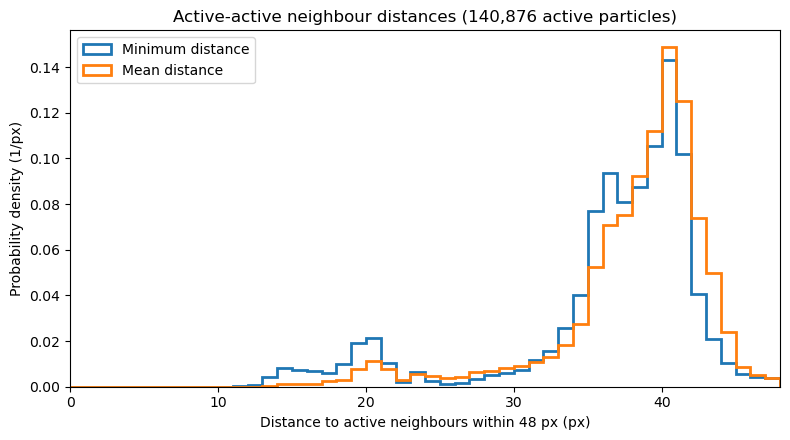

In [13]:
import matplotlib.pyplot as plt

a = df[(df["particle_type"] == "active") & (df["num_AA_neighbors_48px"] >= 1)]
bins = np.arange(0, 49, 1)   # 1 px wide bins from 0 to 48

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(a["local_min_AA_distance_px"], bins=bins, density=True,
        histtype="step", linewidth=2, label="Minimum distance")
ax.hist(a["local_mean_AA_distance_px"], bins=bins, density=True,
        histtype="step", linewidth=2, label="Mean distance")

ax.set_xlabel("Distance to active neighbours within 48 px (px)")
ax.set_ylabel("Probability density (1/px)")
ax.set_title(f"Active-active neighbour distances ({len(a):,} active particles)")
ax.set_xlim(0, 48)
ax.legend()
plt.tight_layout()
plt.savefig("week4_AA_distance_distributions.png", dpi=200)
plt.show()

In [14]:
c = df[(df["frame"] == 51) & (df["cluster_size"] == 3) & (df["N_active"] == 3)]
cluster_id = c["cluster"].iloc[0]
g = c[c["cluster"] == cluster_id]

print("frame 51, cluster", cluster_id)
print(g[["particle_id", "x", "y"]].to_string(index=False))
print("Rg_px in file:", g["Rg_px"].iloc[0])

frame 51, cluster 138410
 particle_id     x       y
        3498 3.207 995.414
        4768 6.500 953.610
        4798 2.200 972.320
Rg_px in file: 17.195991942568725


53 candidate clusters
frame 51, cluster 136137
 particle_id        x        y particle_type
          28  970.293 1022.646        active
         287 1006.247 1044.647        active
        4057  988.932 1031.068       passive
Rg_px in file: 17.25390451141098


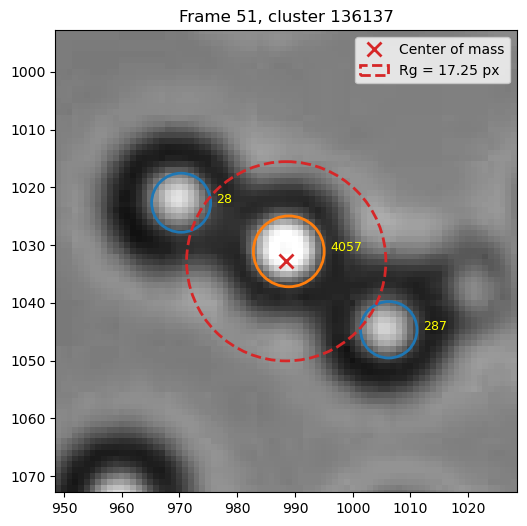

In [18]:
from matplotlib.patches import Circle

IMG_PATH = "/Users/rayyan/Desktop/honors_indep_study/frame51.png"   # same path as before

# --- pick a 3-particle cluster in frame 51 that is away from the image edges ---
margin = 50   # px from any edge
W, H = df["x"].max(), df["y"].max()

c = df[(df["frame"] == 51) & (df["cluster_size"] == 3)]
inside = c.groupby("cluster").filter(
    lambda q: q["x"].between(margin, W - margin).all()
              and q["y"].between(margin, H - margin).all())

print(inside["cluster"].nunique(), "candidate clusters")
if inside.empty:
    raise ValueError("No 3-particle cluster away from the edges in this frame; lower margin or change frame.")

cluster_id = inside["cluster"].iloc[0]
g = inside[inside["cluster"] == cluster_id]

print("frame 51, cluster", cluster_id)
print(g[["particle_id", "x", "y", "particle_type"]].to_string(index=False))
print("Rg_px in file:", g["Rg_px"].iloc[0])

# --- plot ---
cm_x, cm_y, rg = g["cm_x"].iloc[0], g["cm_y"].iloc[0], g["Rg_px"].iloc[0]

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(plt.imread(IMG_PATH), cmap="gray")

for _, p in g.iterrows():
    r = np.sqrt(p["Area"] / np.pi)
    color = "tab:blue" if p["particle_type"] == "active" else "tab:orange"
    ax.add_patch(Circle((p["x"], p["y"]), r, fill=False, color=color, lw=2))
    ax.text(p["x"] + r + 1, p["y"], int(p["particle_id"]), fontsize=9, color="yellow")

ax.plot(cm_x, cm_y, "x", color="tab:red", ms=10, mew=2, label="Center of mass")
ax.add_patch(Circle((cm_x, cm_y), rg, fill=False, color="tab:red", lw=2, ls="--",
                    label=f"Rg = {rg:.2f} px"))

pad = 40
ax.set_xlim(cm_x - pad, cm_x + pad)
ax.set_ylim(cm_y + pad, cm_y - pad)
ax.set_aspect("equal")
ax.legend(loc="upper right")
ax.set_title(f"Frame 51, cluster {cluster_id}")
plt.savefig("week4_Rg_check_cluster.png", dpi=200)
plt.show()